In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:

# 1. Dynamically locate the folder where this script/notebook is running
try:
    script_dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
# Notebook environment fallback (works for VS Code Notebooks & Jupyter)
    script_dir = os.getcwd()

# 2. Point to the CSV file inside your repository folder
target_path = os.path.join(script_dir, "Advertising Budget and Sales.csv")

try:
    df = pd.read_csv(target_path)
    print(f"Dataset successfully loaded from repo path: {target_path}")

    # Fix: Check if the file loaded without text headers
    first_col_name = str(df.columns)
    if (
        first_col_name.replace(".", "", 1).isdigit()
        or "Unnamed" in first_col_name
        or len(df.columns) >= 4
    ):
        print("No text headers detected. Forcing column assignments...")
        if len(df.columns) == 5:
            df.columns = ["Index", "TV", "Radio", "Newspaper", "Sales"]
        elif len(df.columns) == 4:
            df.columns = ["TV", "Radio", "Newspaper", "Sales"]

except FileNotFoundError:
    print(f"File not found at {target_path}. Generating fallback sample data...")
    np.random.seed(42)
    n_samples = 200
    tv = np.random.uniform(10, 300, n_samples)
    radio = np.random.uniform(5, 50, n_samples)
    newspaper = np.random.uniform(2, 100, n_samples)
    sales = (
        5
        + 0.05 * tv
        + 0.18 * radio
        + 0.003 * newspaper
        + np.random.normal(0, 2, n_samples)
    )
    df = pd.DataFrame(
        {"TV": tv, "Radio": radio, "Newspaper": newspaper, "Sales": sales}
    )

# Strip out any remaining indexing columns (Kaggle artifacts)
df = df.loc[:, ~df.columns.str.contains("^Unnamed|^Index", case=False)]

print("\n--- [By Vedansh] Cleaned Dataset Overview ---")
print(df.head())


X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

Dataset successfully loaded from repo path: c:\Users\Lenovo\Downloads\Advertising Budget and Sales.csv
No text headers detected. Forcing column assignments...

--- [By Vedansh] Cleaned Dataset Overview ---
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9


In [3]:
from sklearn.model_selection import train_test_split

"""Splits features into test environments and trains a multi-linear model."""
# Split into Training and Testing Sets (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)

In [4]:
# Check for missing values (NaNs) across all columns
print("Missing values per column:\n", df.isnull().sum())

# Check data types to see if any columns are text/objects instead of numbers
print("\nColumn data types:\n", df.dtypes)

Missing values per column:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Column data types:
 TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression

# Replace NaN values with the median value of that column
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Convert arrays back to DataFrames temporarily just to keep column tracking clean
X_train_imputed_df = pd.DataFrame(X_train_imputed, columns=X.columns)
X_test_imputed_df = pd.DataFrame(X_test_imputed, columns=X.columns)

# Initialize the selector to find the top 3 features based on training labels
selector = SelectKBest(score_func=f_regression, k=3)

# Learn which 3 features are best from the training set, and drop the rest
X_train_selected = selector.fit_transform(X_train_imputed_df, y_train)

# Drop the irrelevant features from the test set using the exact same choices
X_test_selected = selector.transform(X_test_imputed_df)

selected_features = X.columns[selector.get_support()].tolist()
print("Features selected for training:", selected_features)

# Fit the scaler ONLY on training data, then transform both subsets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

# Initialize and Train
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("\n--- [By Deepanshu] Model training complete ---")

Features selected for training: ['TV', 'Radio', 'Newspaper']

--- [By Deepanshu] Model training complete ---


In [6]:
# Identify categorical columns dynamically (if any exist)
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if len(categorical_cols) > 0:
    print(f"Encoding categorical columns: {categorical_cols}")
    df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
else:
    print("No categorical columns found. Dummy encoding is not required for this numerical dataset.")
    df_encoded = df.copy()

No categorical columns found. Dummy encoding is not required for this numerical dataset.


In [7]:
# Computes Pearson correlation and sorts features by their relationship with the target variable
correlation_matrix = df.corr()
print("Correlation with Target:\n", correlation_matrix['Sales'].sort_values(ascending=False))

Correlation with Target:
 Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


In [8]:
def evaluate_and_predict(model,X_test,y_test):
 """Calculates statistical errors and benchmarks custom values"""
 y_pred=model.predict(X_test)

 #Calculate operational metrics 
 mse=mean_squared_error(y_test,y_pred)
 r2=r2_score(y_test,y_pred)

 print("\n---[Srivarsha]Model Evaluation---")
 print(f"intercept:{model.intercept_:.4f}")
 print(f"Coefficients(TV,Radio,Newspaper):{model.coef_}")
 print(f"Mean Squared Error(MSE):{mse:.4f}")
 print(f"R-squared Score(R*2):{r2:.4f}")

 #Run a custom production value prediction 
 #Budget matrix format:[[TVBudget,Radio_Budget,Newspaper_Budget]]
 custom_budget= pd.DataFrame(
     [[200.2,30.0,15.0]],
     columns=['TV',"Radio","Newspaper"]
 )
 custom_pred=model.predict(custom_budget)
 print(f"\ninference Prediction (TV:200,Radio:30,Newspaper:15)->Estimated Sales:{custom_pred[0]:2f}")
 return y_pred

In [14]:
evaluate_and_predict(model ,X_test ,y_test)


---[Srivarsha]Model Evaluation---
intercept:2.9791
Coefficients(TV,Radio,Newspaper):[0.04472952 0.18919505 0.00276111]
Mean Squared Error(MSE):3.1741
R-squared Score(R*2):0.8994

inference Prediction (TV:200,Radio:30,Newspaper:15)->Estimated Sales:17.651185


array([16.4080242 , 20.88988209, 21.55384318, 10.60850256, 22.11237326,
       13.10559172, 21.05719192,  7.46101034, 13.60634581, 15.15506967,
        9.04831992,  6.65328312, 14.34554487,  8.90349333,  9.68959028,
       12.16494386,  8.73628397, 16.26507258, 10.27759582, 18.83109103,
       19.56036653, 13.25103464, 12.33620695, 21.30695132,  7.82740305,
        5.80957448, 20.75753231, 11.98138077,  9.18349576,  8.5066991 ,
       12.46646769, 10.00337695, 21.3876709 , 12.24966368, 18.26661538,
       20.13766267, 14.05514005, 20.85411186, 11.0174441 ,  4.56899622])

In [15]:
def plot_insights(df, y_test, y_pred):
    """Generates analytical charts for budget trends and predictive accuracy."""
    print("\n--- [Jatin] Launching UI Visualization Panels ---")
    plt.figure(figsize=(15, 5))

    # Feature correlation versus target
    features = ["TV", "Radio", "Newspaper"]
    for i, feature in enumerate(features, 1):
        plt.subplot(1, 3, i)
        plt.scatter(df[feature], df["Sales"], color="royalblue", alpha=0.6)
        plt.title(f"{feature} Budget vs Sales")
        plt.xlabel(f"{feature} Budget")
        plt.ylabel("Sales")
        plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Model deviation map
    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, y_pred, color="forestgreen", alpha=0.7, edgecolors="k")
    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--",
        lw=2,
        label="Perfect Prediction Line",
    )
    plt.title("Actual vs Predicted Sales")
    plt.xlabel("Actual Sales")
    plt.ylabel("Predicted Sales")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()



--- [Jatin] Launching UI Visualization Panels ---


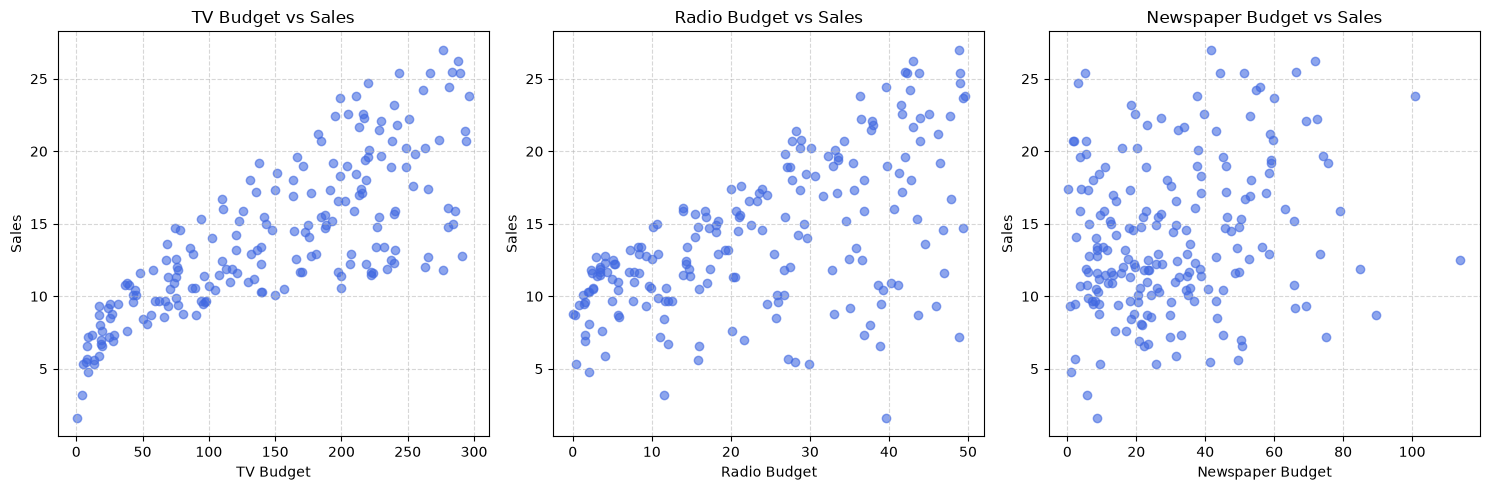

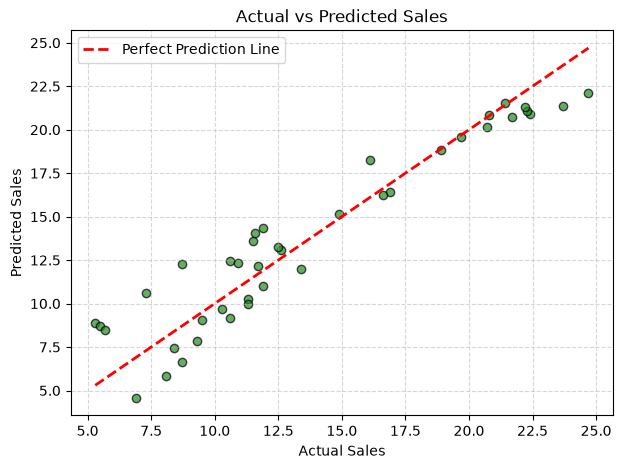

In [18]:
plot_insights(df, y_test, model.predict(X_test))